In [1]:
from IPython.display import display, HTML

display(HTML("""
<style>

.jp-RenderedMarkdown {
    font-family: "Segoe UI", Roboto, sans-serif;
    line-height: 1.6;
}

.jp-RenderedMarkdown h1 {
    text-align: center;
    border-bottom: 3px solid #222;
    padding-bottom: 0.4em;
    margin-top: 0.5em;
}

.jp-RenderedMarkdown h2 {
    border-left: 6px solid #444;
    padding-left: 0.6em;
    margin-top: 1.8em;
}

.jp-RenderedMarkdown h3 {
    margin-top: 1.2em;
    font-weight: 600;
}

table {
    border-collapse: collapse;
}

th, td {
    border: 1px solid #aaa;
    padding: 6px 10px;
}

</style>
"""))

# Raport Laboratori – Elektronikë (LAB02)

**Titulli i Eksperimentit:** Studimi i Ndarësit të Tensionit (Voltage Divider) dhe Efekti i Ngarkesës  
**Lënda:** Hyrje në Elektronikë (Viti III, Fizikë dhe Shkenca Kompjuterike)  
**Pedagogu:** Ervin Kafexhiu dhe Gerti Xhixha  
**Studenti:** Arlind Laçka  
**Data e zhvillimit:** 11.11.2026  
**Data e dorëzimit:** 18.11.2026  

---

## 1. Qëllimi i Eksperimentit

Në këtë laborator u studiua parimi i punës së ndarësit të tensionit duke përdorur dy rezistenca në serí. Qëllimi ishte:
1. Verifikimi i raportit të ndarjes së tensionit për vlera të ulëta rezistencash ($\text{k}\Omega$) dhe vlera të larta ($\text{M}\Omega$).
2. Analizimi i sjelljes së qarkut kur lidhet një rezistencë ngarkese ($R_L$) në dalje ($V_{\text{out}}$) dhe vëzhgimi i rënies së tensionit për shkak të efektit të ngarkesës.

---

## 2. Baza Teorike

Formula e përgjithshme e ndarësit të tensionit pa ngarkesë jepet nga:
$$V_{\text{out}} = V_{\text{in}} \cdot \frac{R_2}{R_1 + R_2}$$

Në pjesën e tretë të eksperimentit, rezistenca e ngarkesës $R_L$ lidhet në paralel me $R_2$, duke ndryshuar rezistencën e përgjithshme ekuivalente të daljes.

---

## 3. Ndërtimi Eksperimental dhe Të Dhënat e Matura

In [2]:
import os
import pandas as pd

# Sigurohemi që folderi data ekziston brenda LAB02
os.makedirs('data', exist_ok=True)

# Krijimi i të dhënave të tri eksperimenteve
# 1. Eksperimenti i parë (kΩ)
# 2. Eksperimenti i dytë (MΩ)
# 3. Eksperimenti i tretë (Ngarkesa RL)

tabela_r1 = pd.DataFrame({
    "Eksperimenti": ["Eksp. 1 (kΩ)", "Eksp. 2 (MΩ)"],
    "R1": ["1.781 kΩ", "3.264 MΩ"],
    "R2": ["1.765 kΩ", "3.229 MΩ"],
    "Vin (V)": [11.36, 11.36],
    "Vout (Pritur V)": [5.68, 5.63],
    "Vout (Matur V)": [5.68, 4.83]
})

tabela_rl = pd.DataFrame({
    "RL (Ω)": [46, 100, 220, 470, 1000],
    "Vout (mV)": [160.0, 348.0, 765.6, 1678.6, 3479.3],
    "Vout (V)": [0.160, 0.348, 0.7656, 1.6786, 3.4793]
})

# Ruajtja e të dhënave në skedarë CSV te folderi data/
tabela_r1.to_csv('data/rezultatet_kryesore.csv', index=False)
tabela_rl.to_csv('data/tabela_ngarkesa_rl.csv', index=False)

print("Të dhënat u përpunuan dhe u ruajtën me sukses te folderi data/!")
tabela_rl

Të dhënat u përpunuan dhe u ruajtën me sukses te folderi data/!


,RL (Ω),Vout (mV),Vout (V)
0,46,160.0,0.1600
1,100,348.0,0.3480
2,220,765.6,0.7656
3,470,1678.6,1.6786
4,1000,3479.3,3.4793


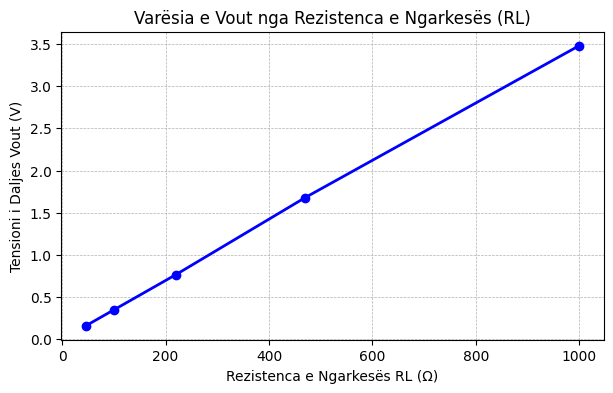

In [3]:
import os
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)

rl_values = [46, 100, 220, 470, 1000]
vout_values = [0.160, 0.348, 0.7656, 1.6786, 3.4793]

plt.figure(figsize=(7, 4))
plt.plot(rl_values, vout_values, marker='o', color='b', linestyle='-', linewidth=2, markersize=6)
plt.title("Varësia e Vout nga Rezistenca e Ngarkesës (RL)")
plt.xlabel("Rezistenca e Ngarkesës RL (Ω)")
plt.ylabel("Tensioni i Daljes Vout (V)")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)

# Ruajtja e figurës në folderin figs/
plt.savefig('figs/grafiku_ngarkesa.png', dpi=300, bbox_inches='tight')
plt.show()